# 01 - Discovery

**TP3 - NLP:** encontrar de qué se habla en un corpus de tweets de 2009 con dos enfoques (BERTopic y KeyBERT + clustering) y contrastar los tópicos con eventos reales.

Esta notebook **solo lee y diagnostica**: no modifica los datos ni guarda nada en `data/processed/`.

Qué responde:
1. ¿De dónde salen los datos y cómo se leen?
2. ¿Qué es cada fila y cada columna?
3. ¿Hay nulos, duplicados o etiquetas contradictorias?
4. ¿Qué período cubren y con qué huecos?
5. ¿Hay usuarios automáticos (bots, spam)?
6. ¿Qué implica todo esto para buscar tópicos?

#### Dependencias

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import utils

#### Parámetros

In [2]:
RANDOM_STATE = 42  # semilla para que los muestreos sean reproducibles

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

#### Funciones

In [3]:
def resumen_columnas(df):
    """Una fila por columna: tipo, nulos, valores únicos y ejemplo."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

## 1. Origen y descarga

- El link de la consigna descarga `trainingandtestdata.zip` con dos CSV. Nombres, columnas y tamaños coinciden con **Sentiment140** ([Go, Bhayani y Huang, 2009](https://cs.stanford.edu/people/alecmgo/papers/TwitterDistantSupervision09.pdf)).
- Según ese trabajo, los tweets en inglés se juntaron con la API de búsqueda de Twitter. La polaridad del archivo grande se asignó **automáticamente por emoticones** (`:)` positivo, `:(` negativo) y después los emoticones se borraron del texto: de ahí `noemoticon`. El archivo chico se etiquetó a mano.
- `utils.descargar_datos()` baja y descomprime los archivos en `data/raw/` solo si no están. Esa carpeta no se sube al repo (~230 MB).

In [4]:
utils.descargar_datos()

for f in sorted(utils.RAW_DIR.iterdir()):
    print(f"{f.name:<45} {f.stat().st_size / 1e6:>7.1f} MB")

testdata.manual.2009.06.14.csv                    0.1 MB
training.1600000.processed.noemoticon.csv       238.8 MB
trainingandtestdata.zip                          81.4 MB


## 2. Lectura

Los CSV no tienen encabezado y están en `latin-1`. Los nombres de columna salen de la descripción de la consigna.

In [5]:
df = utils.leer_tweets(utils.FILE_TRAIN)
df_test = utils.leer_tweets(utils.FILE_TEST)

print(f"Principal (training): {df.shape[0]:>9,} filas x {df.shape[1]} columnas")
print(f"Test (manual):        {df_test.shape[0]:>9,} filas x {df_test.shape[1]} columnas")

Principal (training): 1,600,000 filas x 6 columnas
Test (manual):              498 filas x 6 columnas


In [6]:
df.head()

,polaridad,id,fecha,query,usuario,texto
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D"
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there."


In [7]:
df.sample(8, random_state=RANDOM_STATE)

,polaridad,id,fecha,query,usuario,texto
541200,0,2200003196,Tue Jun 16 18:18:12 PDT 2009,NO_QUERY,LaLaLindsey0609,@chrishasboobs AHHH I HOPE YOUR OK!!!
750,0,1467998485,Mon Apr 06 23:11:14 PDT 2009,NO_QUERY,sexygrneyes,"@misstoriblack cool , i have no tweet apps for my razr 2"
766711,0,2300048954,Tue Jun 23 13:40:11 PDT 2009,NO_QUERY,sammydearr,@TiannaChaos i know just family drama. its lame.hey next time u hang out with kim n u guys like have a sleepover or...
285055,0,1993474027,Mon Jun 01 10:26:07 PDT 2009,NO_QUERY,Lamb_Leanne,School email won't open and I have geography stuff on there to revise! *Stupid School* :'(
705995,0,2256550904,Sat Jun 20 12:56:51 PDT 2009,NO_QUERY,yogicerdito,upper airways problem
379611,0,2052380495,Sat Jun 06 00:32:16 PDT 2009,NO_QUERY,Yengching,Going to miss Pastor's sermon on Faith...
1189018,4,1983449090,Sun May 31 13:10:36 PDT 2009,NO_QUERY,jessig06,on lunch....dj should come eat with me
667030,0,2245479748,Fri Jun 19 16:11:29 PDT 2009,NO_QUERY,felicityfuller,@piginthepoke oh why are you feeling like that?


In [8]:
df_test.head()

,polaridad,id,fecha,query,usuario,texto
0,4,3,Mon May 11 03:17:40 UTC 2009,kindle2,tpryan,"@stellargirl I loooooooovvvvvveee my Kindle2. Not that the DX is cool, but the 2 is fantastic in its own right."
1,4,4,Mon May 11 03:18:03 UTC 2009,kindle2,vcu451,Reading my kindle2... Love it... Lee childs is good read.
2,4,5,Mon May 11 03:18:54 UTC 2009,kindle2,chadfu,"Ok, first assesment of the #kindle2 ...it fucking rocks!!!"
3,4,6,Mon May 11 03:19:04 UTC 2009,kindle2,SIX15,@kenburbary You'll love your Kindle2. I've had mine for a few months and never looked back. The new big one is huge!...
4,4,7,Mon May 11 03:21:41 UTC 2009,kindle2,yamarama,@mikefish Fair enough. But i have the Kindle2 and I think it's perfect :)


## 3. Esquema y tipos

- **Unidad muestral:** un tweet.
- `fecha` se lee como texto e incluye la zona horaria.

In [9]:
resumen_columnas(df)

,dtype,nulos,unicos,ejemplo
polaridad,int64,0,2,0
id,int64,0,1598315,1467810369
fecha,object,0,774363,Mon Apr 06 22:19:45 PDT 2009
query,object,0,1,NO_QUERY
usuario,object,0,659775,_TheSpecialOne_
texto,object,0,1581466,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D"


In [10]:
zonas = pd.DataFrame({
    "principal": df["fecha"].str[20:23].value_counts(),
    "test": df_test["fecha"].str[20:23].value_counts(),
}).fillna(0).astype(int)
zonas

,principal,test
fecha,,
PDT,1600000,0
UTC,0,498


- El archivo principal está en **PDT** (hora del Pacífico, UTC-7) y el de test en **UTC**.
- `utils.parsear_fecha` lleva ambas a PDT. Todas las fechas del TP se expresan en PDT.

In [11]:
df["fecha_pdt"] = utils.parsear_fecha(df["fecha"])
df_test["fecha_pdt"] = utils.parsear_fecha(df_test["fecha"])

pd.DataFrame({
    "desde": [df["fecha_pdt"].min(), df_test["fecha_pdt"].min()],
    "hasta": [df["fecha_pdt"].max(), df_test["fecha_pdt"].max()],
}, index=["principal", "test"])

,desde,hasta
principal,2009-04-06 22:19:45,2009-06-25 10:28:31
test,2009-05-10 20:17:40,2009-06-14 14:36:17


## 4. Nulos y duplicados

In [12]:
pd.DataFrame({
    "nulos": [df.isna().sum().sum(), df_test.isna().sum().sum()],
    "filas duplicadas": [df.duplicated(subset=utils.COLUMNAS).sum(), df_test.duplicated(subset=utils.COLUMNAS).sum()],
    "id duplicado": [df["id"].duplicated().sum(), df_test["id"].duplicated().sum()],
    "texto duplicado": [df["texto"].duplicated().sum(), df_test["texto"].duplicated().sum()],
}, index=["principal", "test"])

,nulos,filas duplicadas,id duplicado,texto duplicado
principal,0,0,1685,18534
test,0,0,0,0


**Ids repetidos:** ¿qué tienen distinto las dos copias?

In [13]:
ids_rep = df[df["id"].duplicated(keep=False)]
print(f"Filas con id repetido: {len(ids_rep):,} ({ids_rep['id'].nunique():,} ids)")
print("Columnas que difieren entre copias:",
      [c for c in utils.COLUMNAS if ids_rep.groupby("id")[c].nunique().gt(1).any()])
ids_rep.groupby("id")["polaridad"].apply(tuple).value_counts()

Filas con id repetido: 3,370 (1,685 ids)
Columnas que difieren entre copias: ['polaridad']


polaridad
(0, 4)    1685
Name: count, dtype: int64

In [14]:
ids_rep.sort_values('id').head(4)

,polaridad,id,fecha,query,usuario,texto,fecha_pdt
213,0,1467863684,Mon Apr 06 22:33:35 PDT 2009,NO_QUERY,DjGundam,Awwh babs... you look so sad underneith that shop entrance of &quot;Yesterday's Musik&quot; O-: I like the look of ...,2009-04-06 22:33:35
800261,4,1467863684,Mon Apr 06 22:33:35 PDT 2009,NO_QUERY,DjGundam,Awwh babs... you look so sad underneith that shop entrance of &quot;Yesterday's Musik&quot; O-: I like the look of ...,2009-04-06 22:33:35
800300,4,1467880442,Mon Apr 06 22:38:04 PDT 2009,NO_QUERY,iCalvin,"Haven't tweeted nearly all day Posted my website tonight, hopefully that goes well Night time!",2009-04-06 22:38:04
275,0,1467880442,Mon Apr 06 22:38:04 PDT 2009,NO_QUERY,iCalvin,"Haven't tweeted nearly all day Posted my website tonight, hopefully that goes well Night time!",2009-04-06 22:38:04


- Cada id repetido aparece **una vez como negativo y otra como positivo**, con el mismo texto: probablemente el tweet tenía emoticones de los dos tipos.
- Para tópicos la polaridad no se usa, pero son tweets duplicados: hay que dejar una sola copia.

**Textos repetidos:** los más frecuentes.

In [15]:
df['texto'].value_counts().head(15)

texto
isPlayer Has Died! Sorry                                                                                   210
good morning                                                                                               118
headache                                                                                                   115
Good morning                                                                                               112
Headache                                                                                                   106
Not to worry, noone got that one. Next question starts in 1 minute, get your thinking caps on               86
 cant afford to see Angels and Demons, so i watched it for free: http://tr.im/lvBu                          86
Goodnight                                                                                                   85
my tummy hurts                                                                                            

- Hay dos tipos de repetición:
  - **Frases cortas** de la vida diaria (`good morning`, `headache`, `at work`): no aportan información sobre temas.
  - **Mensajes automáticos** (`isPlayer Has Died!`, preguntas de trivia, publicidad de *Angels and Demons*): pueden formar tópicos artificiales.
- `Good morning` y `good morning` cuentan por separado: después de limpiar (minúsculas, sin menciones ni URLs) va a haber más duplicados.

## 5. Polaridad y `query`

In [16]:
pd.DataFrame({
    "principal": df["polaridad"].value_counts(),
    "test": df_test["polaridad"].value_counts(),
}).fillna(0).astype(int).sort_index()

,principal,test
polaridad,,
0,800000,177
2,0,139
4,800000,182


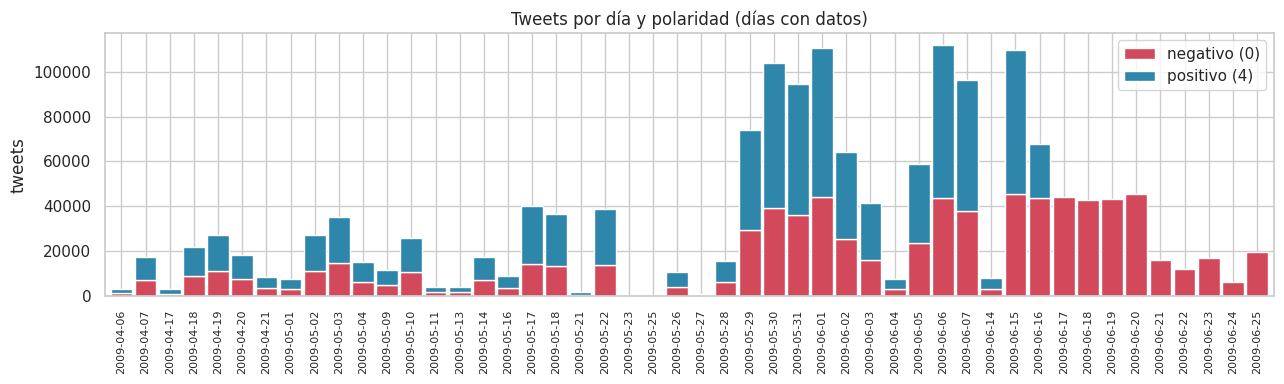

Último tweet positivo: 2009-06-16 08:40:50


In [17]:
por_dia = pd.crosstab(df["fecha_pdt"].dt.date, df["polaridad"])
fig, ax = plt.subplots(figsize=(13, 4))
por_dia.plot(kind="bar", stacked=True, ax=ax, width=0.9, color=["#d1495b", "#2e86ab"])
ax.set(title="Tweets por día y polaridad (días con datos)", xlabel="", ylabel="tweets")
ax.legend(["negativo (0)", "positivo (4)"])
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

print("Último tweet positivo:", df.loc[df["polaridad"] == 4, "fecha_pdt"].max())

- En total está **balanceado 50/50**, pero **no en el tiempo**: los positivos terminan el 16/6 y los últimos días solo tienen negativos.
- El balance se armó a propósito al construir el dataset. Consecuencia: el volumen por día **no refleja** cuánto se tuiteó ese día, y en la última semana el tono es solo negativo.

In [18]:
print("query en el archivo principal:", df["query"].unique())
print(f"query en test: {df_test['query'].nunique()} valores distintos")
df_test["query"].value_counts().head(10)

query en el archivo principal: ['NO_QUERY']
query en test: 81 valores distintos


query
time warner              35
"night at the museum"    25
nike                     25
gm                       22
kindle2                  20
safeway                  20
lebron                   18
dentist                  17
jquery                   16
at&t                     15
Name: count, dtype: int64

- En el archivo principal `query` vale siempre `NO_QUERY`: **no aporta información**.
- El de test se juntó buscando marcas, productos y personas (`kindle2`, `nike`, `lebron`...). Son pocos tweets (498) y de un período más corto, pero sirven para un control: ¿los tweets de una misma búsqueda caen en el mismo tópico?

## 6. Período y huecos

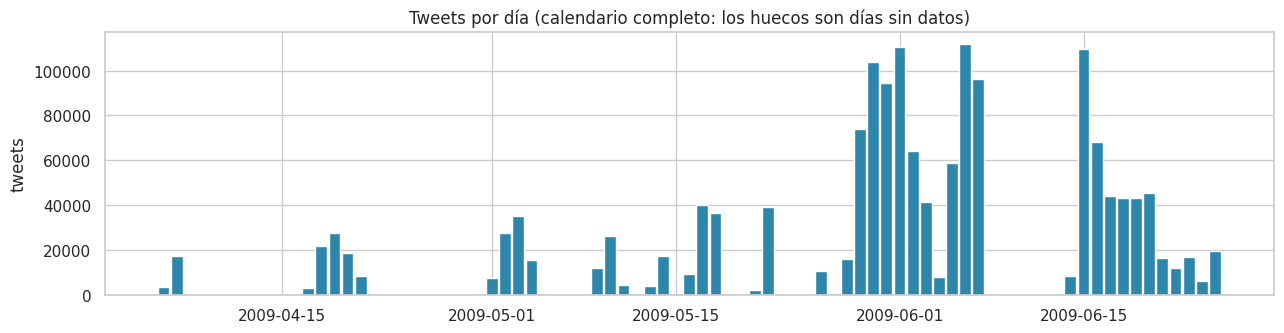

Días del período: 81 | días con datos: 48


In [19]:
calendario = pd.date_range(df["fecha_pdt"].min().normalize(), df["fecha_pdt"].max().normalize(), freq="D")
tweets_dia = df["fecha_pdt"].dt.normalize().value_counts().reindex(calendario, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(tweets_dia.index, tweets_dia.values, width=0.9, color="#2e86ab")
ax.set(title="Tweets por día (calendario completo: los huecos son días sin datos)", ylabel="tweets")
plt.tight_layout()
plt.show()

print(f"Días del período: {len(calendario)} | días con datos: {(tweets_dia > 0).sum()}")

In [20]:
vacios = tweets_dia[tweets_dia == 0].index.to_series()
bloques = (vacios.diff() != pd.Timedelta(days=1)).cumsum()
huecos = vacios.groupby(bloques).agg(["min", "max", "count"])
huecos.columns = ["desde", "hasta", "días"]
huecos.reset_index(drop=True)

,desde,hasta,días
0,2009-04-08,2009-04-16,9
1,2009-04-22,2009-04-30,9
2,2009-05-05,2009-05-08,4
3,2009-05-12,2009-05-12,1
4,2009-05-15,2009-05-15,1
5,2009-05-19,2009-05-20,2
6,2009-05-24,2009-05-24,1
7,2009-06-08,2009-06-13,6


In [21]:
print("Volumen por mes (% del total):")
(df["fecha_pdt"].dt.month_name().value_counts(normalize=True) * 100).round(1)

Volumen por mes (% del total):


fecha_pdt
June     57.7
May      36.0
April     6.3
Name: proportion, dtype: float64

- Cubre del **6/4 al 25/6/2009**, pero solo **48 de 81 días** tienen tweets. Los huecos más largos: 8–16/4, 22–30/4 (9 días cada uno) y 8–13/6 (6 días).
- El volumen se concentra en **fines de mayo y junio**. Abril tiene pocos tweets.
- Un evento que cae en un hueco **no puede aparecer**. Tampoco nada posterior al **25/6 a las 10:28 PDT**: por ejemplo, la muerte de Michael Jackson fue esa misma tarde ([Wikipedia](https://en.wikipedia.org/wiki/Death_of_Michael_Jackson)).
- Para comparar días hay que usar **proporciones** (tweets de un tópico / tweets del día) y no conteos.

## 7. Usuarios

In [22]:
por_usuario = df["usuario"].value_counts()
print(f"Usuarios distintos: {len(por_usuario):,}")
print(f"Con 1 solo tweet: {(por_usuario == 1).mean():.1%} | con 10 o menos: {(por_usuario <= 10).mean():.1%}")
por_usuario.describe().round(1)

Usuarios distintos: 659,775
Con 1 solo tweet: 61.4% | con 10 o menos: 97.2%


count    659775.0
mean          2.4
std           4.7
min           1.0
25%           1.0
50%           1.0
75%           2.0
max         549.0
Name: count, dtype: float64

In [23]:
top = por_usuario.head(10).rename("tweets").to_frame()
top["textos distintos"] = df[df["usuario"].isin(top.index)].groupby("usuario")["texto"].nunique()
top["ejemplo"] = df[df["usuario"].isin(top.index)].groupby("usuario")["texto"].first()
top

,tweets,textos distintos,ejemplo
usuario,,,
lost_dog,549,549,@NyleW I am lost. Please help me find a good home.
webwoke,345,341,"auchh, drop by 1 (32)elitestv.com"
tweetpet,310,79,@tweetchild Clean Me!
SallytheShizzle,281,281,@OfficialAS without ASA....i'm sorry if you didn't know that already
VioletsCRUK,279,279,@jason_2008 Hello! Im out of coffee this morning..that's what i get for winding you up yesterday!!! Lol Have a good...
mcraddictal,276,274,@mcr_chick i wanna sleep.lol. Urgh. I feel like crying
tsarnick,248,248,@MissxMarisa haven't heard from Hannah at all yet!! it's very disappointing
what_bugs_u,246,246,"@JadeMcCray why limit your story to 140 chr. Tell all what is annoying you at www.iamsoannoyed.com ,it will help rel..."
Karen230683,238,238,@KingKiwi i want to be somewhere with no rain its not very nice here today


- La gran mayoría de los usuarios tiene pocos tweets.
- Entre los que más publican hay **cuentas automáticas** que repiten una plantilla cambiando la mención o el link (`lost_dog`, `webwoke`, `tweetpet`). Al quitar menciones y URLs quedan textos idénticos, así que la deduplicación de la notebook 03 las reduce a una o pocas filas.

## 8. Calidad del texto

In [24]:
patrones = {
    "menciones (@usuario)": r"@\w",
    "URLs": r"http|www\.",
    "hashtags": r"#\w",
    "entidades HTML (&amp; &quot; &lt;)": r"&(?:amp|quot|lt|gt);",
    "caracteres rotos (ï¿½)": "ï¿½",
}
pd.Series({k: df["texto"].str.contains(v).mean() * 100 for k, v in patrones.items()},
          name="% de tweets").round(2).to_frame()

,% de tweets
menciones (@usuario),46.16
URLs,4.78
hashtags,2.24
entidades HTML (&amp; &quot; &lt;),5.90
caracteres rotos (ï¿½),0.25


In [25]:
df.loc[df["texto"].str.contains("ï¿½"), "texto"].head(5).tolist()

['@JonathanRKnight I hate the limited letters,too.Hope you and the guys are fine?I pray for my dog,sheï¿½s not well ',
 'Tuesdayï¿½ll start with reflection ï¿½n then a lecture in Stress reducing techniques. That sure might become very useful for us accompaniers ',
 '@DonnieWahlberg ooh Iï¿½m excited and not even going 2 be there  long love YOUTUBE!',
 'Time to move my posterior  and lose some fat. My articulation are creaking so no more running  but Iï¿½m drool for some swimming',
 '@Sofii_Noel thatï¿½s bad ']

In [26]:
largo = df["texto"].str.len()
largo.describe().round(1)

count    1600000.0
mean          74.1
std           36.4
min            6.0
25%           44.0
50%           69.0
75%          104.0
max          374.0
Name: texto, dtype: float64

- Casi la mitad de los tweets **menciona a otro usuario**: es mucha charla entre personas.
- Los **hashtags son pocos** (~2%): no alcanzan para encontrar temas solos.
- Hay **entidades HTML** (`&amp;`, `&quot;`) y caracteres rotos `ï¿½` (casi siempre un apóstrofe perdido: `sheï¿½s`). Se corrigen en la limpieza.
- Los textos son cortos (mediana de 69 caracteres): cada tweet tiene poco contexto.

## 9. Conclusiones del discovery

| Hallazgo | Implicancia | Dónde se resuelve |
| --- | --- | --- |
| 1,6 M de tweets en inglés, sin nulos | Demasiado para embeddings en CPU | 03: muestra estratificada por día |
| Fechas en PDT y en UTC según el archivo | Hay que unificar la zona horaria | `utils.parsear_fecha` (todo en PDT) |
| 1.685 ids repetidos con polaridad opuesta | Duplicados | 03: deduplicar |
| ~18.500 textos repetidos (frases cortas y plantillas) | Ruido y tópicos artificiales | 03: deduplicar después de limpiar y filtrar textos cortos |
| Cuentas automáticas (`lost_dog`, `webwoke`...) | Tópicos artificiales | 03: deduplicar después de quitar menciones y URLs |
| 48 de 81 días con datos; volumen desparejo | Eventos en huecos no pueden aparecer | 02 y 04: usar proporciones por día |
| Polaridad balanceada en total pero no en el tiempo | El volumen diario no es natural | Tenerlo en cuenta al interpretar picos |
| `query` constante en el archivo principal | No aporta | Se descarta |
| Test: 498 tweets etiquetados por `query` | Control externo | 06: ¿cada `query` cae en un mismo tópico? |
| Menciones, URLs, `&amp;`, `ï¿½` en el texto | Ruido para el vectorizador | 03: limpieza |
| Etiquetas puestas por emoticones | Sesgo: domina la charla personal, los eventos son minoría | Limitación a reportar |